# 📘 6.1 Newton–Cotes Integration

### Estimating accumulated engineering quantities from sampled data

Engineering measurements often describe a **rate**, **load** or **density** rather
than the accumulated quantity we need:

* thrust varies with time, but total impulse is required;
* force varies with displacement, but mechanical work is required;
* power varies with time, but energy consumption is required;
* pressure varies along a surface, but a resultant force is required; and
* mass flow varies with time, but total transferred mass is required.

A definite integral converts this distributed information into an accumulated
quantity. When only sampled values are available, **Newton–Cotes rules** approximate
the integrand between sample locations and integrate that approximation.

This notebook develops the trapezoidal rule and Simpson's 1/3 rule from both a
mathematical and engineering perspective. The detailed study of integration error is
reserved for Notebook 6.2.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain a definite integral as an accumulated engineering quantity;
* identify the integration variable, bounds, integrand and physical units;
* explain the interpolating-polynomial idea behind closed Newton–Cotes rules;
* implement single-panel and composite trapezoidal integration;
* implement composite Simpson's 1/3 rule for equally spaced samples;
* use `scipy.integrate.trapezoid`, `simpson` and `cumulative_trapezoid`;
* recognise sample-count, spacing and ordering requirements; and
* communicate what a numerical integral can and cannot establish from sampled data.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* NIST Digital Library of Mathematical Functions — [Quadrature](https://dlmf.nist.gov/3.5)
* SciPy — [`integrate.trapezoid`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html)
* SciPy — [`integrate.simpson`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html)
* SciPy — [`integrate.cumulative_trapezoid`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.cumulative_trapezoid.html)
* NumPy — [`trapezoid`](https://numpy.org/doc/stable/reference/generated/numpy.trapezoid.html)
* NASA Glenn Research Center — [Specific impulse and total impulse](https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/specific-impulse/)


## 📂 6.1.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no
cell requires editing or typed input.

The separate Week 6 workbook will contain activities to begin in Monday's workshop,
continue in Wednesday's practical, and finish during revision at home.


### 📖 Core language for 6.1

Throughout this notebook:

* the **integrand** is the function or sampled quantity being accumulated;
* the **integration variable** is the coordinate over which accumulation occurs;
* the **bounds** define the interval from $a$ to $b$;
* a **node** is a location where the integrand is known;
* a **panel** is one interval, or one group of intervals, used by a rule;
* a **quadrature rule** is a weighted sum used to approximate an integral;
* a **closed Newton–Cotes rule** includes the endpoints of its panel;
* a **composite rule** applies a lower-order rule repeatedly across the domain; and
* **cumulative integration** reports the accumulated quantity at each successive node.


## 📂 6.1.1 From a continuous integral to sampled data

For a continuous function $f(x)$, the definite integral is

$$
I = \int_a^b f(x)\,\mathrm{d}x.
$$

Its units are the units of $f$ multiplied by the units of $x$. For example:

| Integrand | Variable | Integral | Units |
|---|---|---|---|
| force [N] | displacement [m] | work | N m = J |
| power [W] | time [s] | energy | W s = J |
| thrust [N] | time [s] | impulse | N s |
| mass flow [kg/s] | time [s] | transferred mass | kg |

In experimental work, we usually know $f$ only at discrete nodes
$(x_0,f_0),\ldots,(x_n,f_n)$. Numerical integration estimates the area between and
beneath those samples.


In [ ]:
%matplotlib inline

from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid, simpson, trapezoid

pd.set_option("display.precision", 5)


## 📂 6.1.2 Engineering example: rocket-motor total impulse

Rocket thrust changes during a burn. NASA defines total impulse as the time integral
of thrust:

$$
I_{\mathrm{total}} = \int_{t_0}^{t_f} F(t)\,\mathrm{d}t.
$$

Here:

* **integrand:** thrust $F(t)$ in newtons;
* **integration variable:** time $t$ in seconds;
* **bounds:** ignition time $t_0$ to final burn time $t_f$; and
* **output:** total impulse in newton-seconds.

The dataset below is **synthetic and deterministic**. It resembles a smooth
thrust-time trace sampled every 0.5 s. It is not test data for a real motor and must
not be used for propulsion design.


In [ ]:
def underlying_thrust_N(time_s):
    # Synthetic smooth thrust curve used only to generate teaching data.
    time_s = np.asarray(time_s, dtype=float)
    burn_duration_s = 10.0

    rise = 1.0 - np.exp(-2.8 * time_s)
    decay = 1.0 - np.exp(-2.2 * (burn_duration_s - time_s))
    modulation = 1.0 + 0.035 * np.sin(1.25 * time_s)
    thrust = 1180.0 * rise * decay * modulation

    return np.where(
        (time_s >= 0.0) & (time_s <= burn_duration_s),
        np.maximum(thrust, 0.0),
        0.0,
    )


sample_time_s = np.linspace(0.0, 10.0, 21)
measured_thrust_N = underlying_thrust_N(sample_time_s)

# Small deterministic measurement-like deviations.
measured_thrust_N += np.array([
     0,  10, -12,   8,  -6,   5,  11,
    -9,   6,  -7,   4,   8, -10,   7,
    -5,   9,  -8,   5,  -4,   3,   0,
])
measured_thrust_N[[0, -1]] = 0.0

thrust_data = pd.DataFrame({
    "time_s": sample_time_s,
    "thrust_N": measured_thrust_N,
})

thrust_data.head(8)


,time_s,thrust_N
0,0.0,0.00000
1,0.5,917.22120
2,1.0,1133.05386
3,1.5,1209.11807
4,2.0,1194.26199
5,2.5,1184.60852
6,3.0,1167.13425
7,3.5,1131.96443


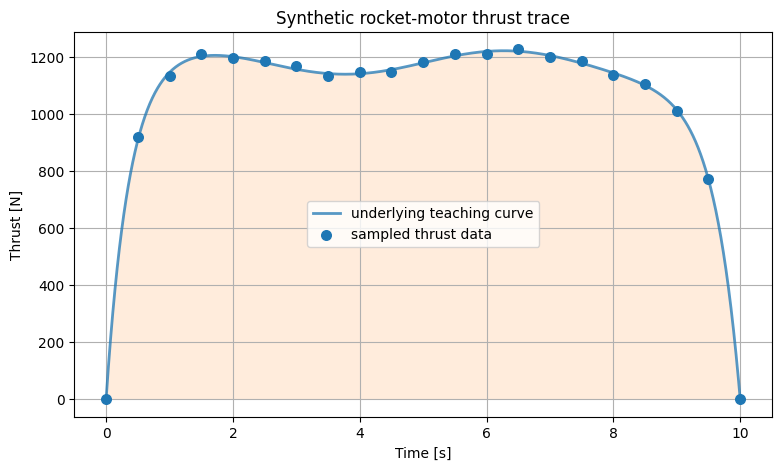

In [ ]:
dense_time_s = np.linspace(0.0, 10.0, 2001)
dense_thrust_N = underlying_thrust_N(dense_time_s)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    dense_time_s,
    dense_thrust_N,
    linewidth=2.0,
    alpha=0.75,
    label="underlying teaching curve",
)
ax.scatter(
    sample_time_s,
    measured_thrust_N,
    s=48,
    zorder=3,
    label="sampled thrust data",
)
ax.fill_between(dense_time_s, dense_thrust_N, alpha=0.14)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title("Synthetic rocket-motor thrust trace")
ax.grid(True)
ax.legend()

plt.show()


### 🧠 What should you notice?

The desired result is not the thrust at one time. It is the accumulated area under
the complete thrust-time curve.

We know only the sampled points. Any area placed between them depends on an assumed
shape. Newton–Cotes rules make that assumption explicit through an interpolating
polynomial.


## 📂 6.1.3 The Newton–Cotes idea

Newton–Cotes rules follow three steps:

1. choose equally spaced nodes in an interval;
2. construct a polynomial through the sampled values; and
3. integrate that polynomial exactly.

The result is a weighted sum

$$
\int_a^b f(x)\,\mathrm{d}x \approx \sum_{i=0}^{n} w_i f(x_i),
$$

where the weights $w_i$ depend on the node locations and selected rule.

The trapezoidal rule integrates a straight-line interpolant. Simpson's 1/3 rule
integrates a quadratic interpolant. In practice, both are normally used as
**composite rules** rather than fitting one high-degree polynomial across the whole
dataset.


## 📂 6.1.4 One trapezoidal panel

Between two nodes $(x_i,f_i)$ and $(x_{i+1},f_{i+1})$, the trapezoidal rule assumes
that $f$ changes linearly. The estimated area is

$$
I_i \approx \frac{x_{i+1}-x_i}{2}\left(f_i+f_{i+1}\right).
$$

This is the width of the interval multiplied by the average endpoint height.


In [ ]:
panel_index = 5
x_left = sample_time_s[panel_index]
x_right = sample_time_s[panel_index + 1]
y_left = measured_thrust_N[panel_index]
y_right = measured_thrust_N[panel_index + 1]

panel_impulse_Ns = (x_right - x_left) * (y_left + y_right) / 2.0

panel_summary = pd.DataFrame({
    "quantity": ["left time", "right time", "panel width", "panel impulse"],
    "value": [x_left, x_right, x_right - x_left, panel_impulse_Ns],
    "units": ["s", "s", "s", "N s"],
})

panel_summary


,quantity,value,units
0,left time,2.50000,s
1,right time,3.00000,s
2,panel width,0.50000,s
3,panel impulse,587.93569,N s


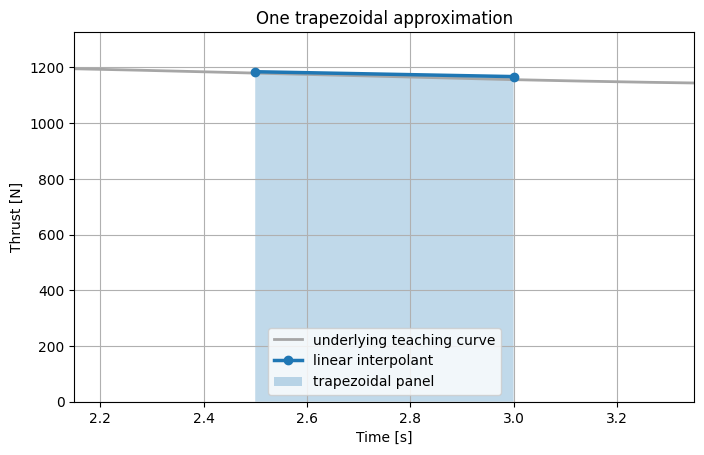

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))

ax.plot(
    dense_time_s,
    dense_thrust_N,
    color="0.65",
    linewidth=2,
    label="underlying teaching curve",
)
ax.plot(
    [x_left, x_right],
    [y_left, y_right],
    marker="o",
    linewidth=2.5,
    label="linear interpolant",
)
ax.fill(
    [x_left, x_left, x_right, x_right],
    [0.0, y_left, y_right, 0.0],
    alpha=0.28,
    label="trapezoidal panel",
)

ax.set_xlim(x_left - 0.35, x_right + 0.35)
ax.set_ylim(0.0, 1.12 * max(y_left, y_right))
ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title("One trapezoidal approximation")
ax.grid(True)
ax.legend()

plt.show()


## 📂 6.1.5 Composite trapezoidal rule

Applying a trapezoid to every adjacent pair gives

$$
I \approx \sum_{i=0}^{n-1}
\frac{x_{i+1}-x_i}{2}\left(f_i+f_{i+1}\right).
$$

This form works for unequal spacing because each panel uses its own width. For equal
spacing $h$, it can also be written

$$
I \approx h\left[\frac{f_0}{2} + f_1 + \cdots + f_{n-1}
+ \frac{f_n}{2}\right].
$$


In [ ]:
def composite_trapezoid_manual(x, y):
    # Integrate ordered samples using adjacent trapezoidal panels.
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1 or x.size != y.size:
        raise ValueError("x and y must be one-dimensional arrays of equal length")
    if x.size < 2:
        raise ValueError("at least two samples are required")
    if not np.all(np.diff(x) > 0.0):
        raise ValueError("x must be strictly increasing")

    widths = np.diff(x)
    average_heights = 0.5 * (y[:-1] + y[1:])
    return np.sum(widths * average_heights)


impulse_trapezoid_manual_Ns = composite_trapezoid_manual(
    sample_time_s,
    measured_thrust_N,
)
impulse_trapezoid_scipy_Ns = trapezoid(
    measured_thrust_N,
    x=sample_time_s,
)

pd.DataFrame({
    "implementation": ["manual composite rule", "scipy.integrate.trapezoid"],
    "total_impulse_Ns": [
        impulse_trapezoid_manual_Ns,
        impulse_trapezoid_scipy_Ns,
    ],
})


,implementation,total_impulse_Ns
0,manual composite rule,10733.65729
1,scipy.integrate.trapezoid,10733.65729


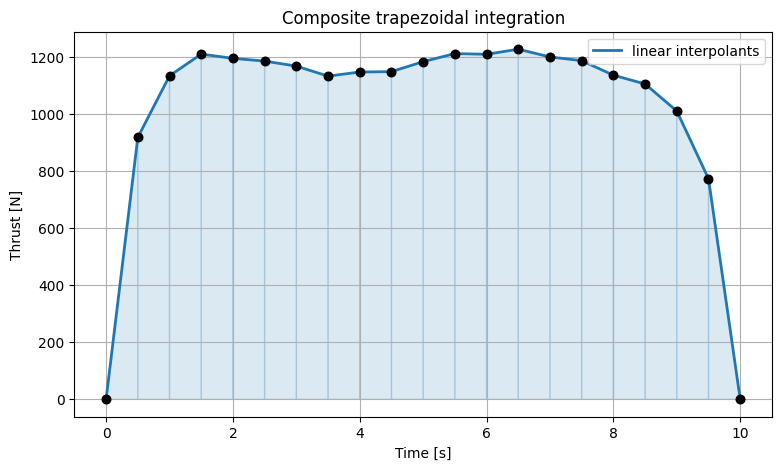

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(sample_time_s, measured_thrust_N, s=38, color="black", zorder=3)
ax.plot(sample_time_s, measured_thrust_N, linewidth=2.0, label="linear interpolants")

for i in range(len(sample_time_s) - 1):
    ax.fill(
        [sample_time_s[i], sample_time_s[i], sample_time_s[i + 1], sample_time_s[i + 1]],
        [0.0, measured_thrust_N[i], measured_thrust_N[i + 1], 0.0],
        alpha=0.16,
        color="tab:blue",
    )

ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title("Composite trapezoidal integration")
ax.grid(True)
ax.legend()

plt.show()


### 🧠 Why keep the manual implementation?

The manual function reveals the numerical method: calculate each panel width,
multiply it by the average endpoint height, then sum the panel contributions.

The library function is preferable for routine work because it is concise and
tested. Agreement between two implementations is a useful **code verification**
check, although it does not prove that the sampled data adequately represent the
physical thrust curve.


## 📂 6.1.6 One Simpson's 1/3 panel

Simpson's 1/3 rule uses three equally spaced nodes across two intervals. It fits a
quadratic through the three values and integrates that quadratic:

$$
\int_{x_0}^{x_2} f(x)\,\mathrm{d}x
\approx \frac{h}{3}\left(f_0+4f_1+f_2\right),
$$

where $h=x_1-x_0=x_2-x_1$.

The middle value receives four times the endpoint weight because it controls the
curvature of the quadratic interpolant.


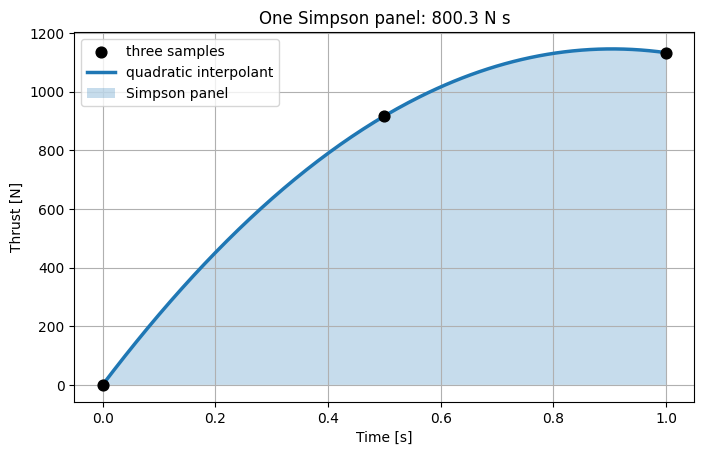

In [ ]:
simpson_panel_start = 0
panel_x = sample_time_s[simpson_panel_start:simpson_panel_start + 3]
panel_y = measured_thrust_N[simpson_panel_start:simpson_panel_start + 3]
panel_h = panel_x[1] - panel_x[0]

simpson_panel_impulse_Ns = panel_h / 3.0 * (
    panel_y[0] + 4.0 * panel_y[1] + panel_y[2]
)

quadratic_coefficients = np.polyfit(panel_x, panel_y, deg=2)
panel_dense_x = np.linspace(panel_x[0], panel_x[-1], 200)
panel_dense_y = np.polyval(quadratic_coefficients, panel_dense_x)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(panel_x, panel_y, color="black", s=60, zorder=3, label="three samples")
ax.plot(panel_dense_x, panel_dense_y, linewidth=2.5, label="quadratic interpolant")
ax.fill_between(panel_dense_x, panel_dense_y, alpha=0.25, label="Simpson panel")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title(f"One Simpson panel: {simpson_panel_impulse_Ns:.1f} N s")
ax.grid(True)
ax.legend()

plt.show()


## 📂 6.1.7 Composite Simpson's 1/3 rule

For $n$ equal-width intervals, where $n$ is even, the composite formula is

$$
I \approx \frac{h}{3}\left[
f_0
+4\sum_{i\ \mathrm{odd}} f_i
+2\sum_{i\ \mathrm{even},\ i\ne 0,n}f_i
+f_n
\right].
$$

The classical composite rule therefore requires:

* equally spaced nodes;
* an even number of intervals; and
* an odd number of samples.

`scipy.integrate.simpson` can also operate on unequally spaced samples, but the
familiar $1,4,2,4,\ldots,2,4,1$ weighting above belongs to the equally spaced rule.


In [ ]:
def composite_simpson_uniform_manual(x, y):
    # Composite Simpson's 1/3 rule for ordered, equally spaced samples.
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1 or x.size != y.size:
        raise ValueError("x and y must be one-dimensional arrays of equal length")
    if x.size < 3:
        raise ValueError("at least three samples are required")
    if (x.size - 1) % 2 != 0:
        raise ValueError("Simpson's 1/3 rule requires an even number of intervals")

    spacing = np.diff(x)
    if not np.all(spacing > 0.0):
        raise ValueError("x must be strictly increasing")
    if not np.allclose(spacing, spacing[0]):
        raise ValueError("this textbook implementation requires equal spacing")

    h = spacing[0]
    odd_sum = np.sum(y[1:-1:2])
    even_sum = np.sum(y[2:-1:2])
    return h / 3.0 * (y[0] + 4.0 * odd_sum + 2.0 * even_sum + y[-1])


impulse_simpson_manual_Ns = composite_simpson_uniform_manual(
    sample_time_s,
    measured_thrust_N,
)
impulse_simpson_scipy_Ns = simpson(
    measured_thrust_N,
    x=sample_time_s,
)

pd.DataFrame({
    "implementation": ["manual composite rule", "scipy.integrate.simpson"],
    "total_impulse_Ns": [impulse_simpson_manual_Ns, impulse_simpson_scipy_Ns],
})


,implementation,total_impulse_Ns
0,manual composite rule,10852.81458
1,scipy.integrate.simpson,10852.81458


### ⚠️ Sample-count warning

Twenty-one samples create twenty intervals, so the classical composite Simpson rule
can cover the complete dataset.

If one sample were removed, there would be nineteen intervals. Our manual function
would reject that input rather than silently applying a different rule. SciPy's
current implementation handles the final unmatched interval using an additional
correction. When reporting work, state the function used rather than assuming every
implementation applies identical endpoint logic.


## 📂 6.1.8 Compare the estimates

Because this teaching dataset was generated from a known smooth function, we can
calculate a dense numerical reference for the underlying curve. This is useful for
demonstration.

In a real experiment, the underlying curve is unknown. A very fine calculation of an
assumed curve is not independent physical ground truth.


In [ ]:
reference_impulse_Ns = trapezoid(dense_thrust_N, x=dense_time_s)

integration_comparison = pd.DataFrame({
    "method": [
        "composite trapezoidal rule",
        "composite Simpson's 1/3 rule",
        "dense generating-curve reference",
    ],
    "total_impulse_Ns": [
        impulse_trapezoid_scipy_Ns,
        impulse_simpson_scipy_Ns,
        reference_impulse_Ns,
    ],
})
integration_comparison["difference_from_reference_Ns"] = (
    integration_comparison["total_impulse_Ns"] - reference_impulse_Ns
)

integration_comparison


,method,total_impulse_Ns,difference_from_reference_Ns
0,composite trapezoidal rule,10733.65729,-112.10711
1,composite Simpson's 1/3 rule,10852.81458,7.05018
2,dense generating-curve reference,10845.76440,0.00000


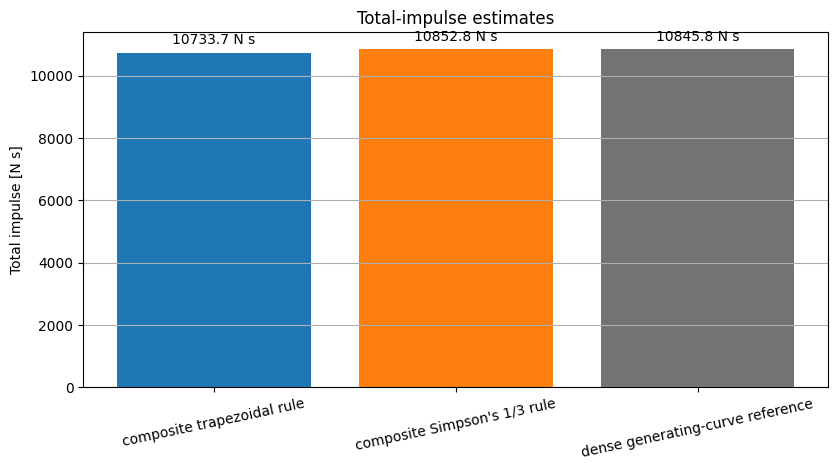

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))

colours = ["tab:blue", "tab:orange", "0.45"]
bars = ax.bar(
    integration_comparison["method"],
    integration_comparison["total_impulse_Ns"],
    color=colours,
)
ax.bar_label(bars, fmt="%.1f N s", padding=4)
ax.set_ylabel("Total impulse [N s]")
ax.set_title("Total-impulse estimates")
ax.grid(True, axis="y")
ax.tick_params(axis="x", rotation=12)

plt.tight_layout()
plt.show()


### 🧠 Interpretation

Both rules use exactly the same measured samples. Their results differ because they
assume different shapes between the nodes:

* the trapezoidal rule uses straight segments; and
* Simpson's rule uses local quadratics.

Simpson's rule is often more accurate for smooth functions with equally spaced data,
but it is not automatically superior when measurements are noisy, poorly ordered or
too sparse to represent important behaviour. Notebook 6.2 will investigate these
error questions systematically.


## 📂 6.1.9 Cumulative integration

Sometimes the final integral is not enough. We may need the accumulated quantity as a
function of the integration variable:

$$
I(t_k)=\int_{t_0}^{t_k}F(t)\,\mathrm{d}t.
$$

`cumulative_trapezoid(..., initial=0.0)` returns an array with the same length as the
input samples. The value begins at zero and increases as positive thrust accumulates.


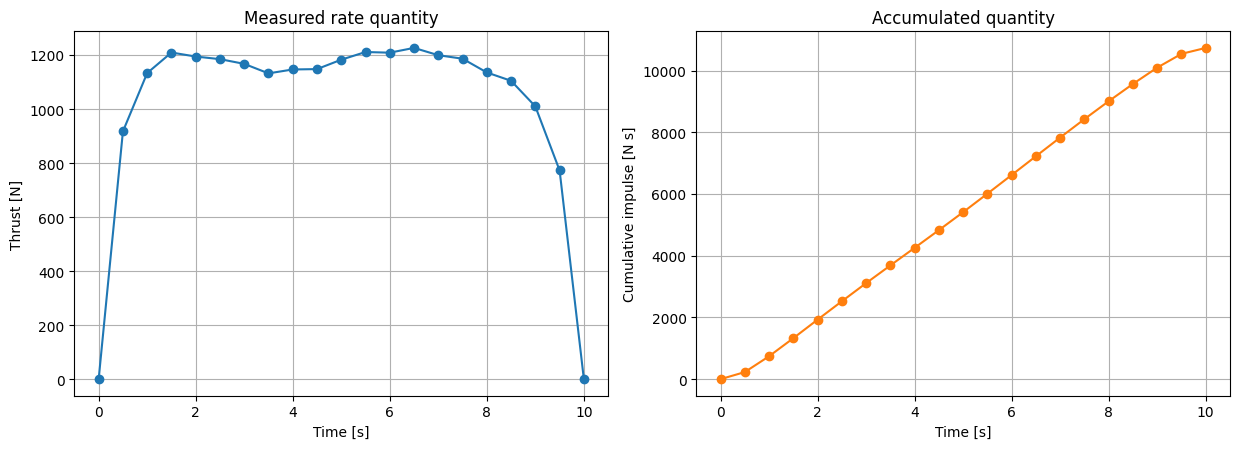

,time_s,thrust_N,cumulative_impulse_Ns
15,7.5,1186.22419,8426.06262
16,8.0,1135.32051,9006.44880
17,8.5,1104.40120,9566.37923
18,9.0,1009.71066,10094.90719
19,9.5,772.64487,10540.49607
20,10.0,0.00000,10733.65729


In [ ]:
cumulative_impulse_Ns = cumulative_trapezoid(
    measured_thrust_N,
    x=sample_time_s,
    initial=0.0,
)

cumulative_data = thrust_data.copy()
cumulative_data["cumulative_impulse_Ns"] = cumulative_impulse_Ns

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

axes[0].plot(sample_time_s, measured_thrust_N, marker="o")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Thrust [N]")
axes[0].set_title("Measured rate quantity")
axes[0].grid(True)

axes[1].plot(sample_time_s, cumulative_impulse_Ns, marker="o", color="tab:orange")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Cumulative impulse [N s]")
axes[1].set_title("Accumulated quantity")
axes[1].grid(True)

plt.tight_layout()
plt.show()

cumulative_data.tail(6)


## 📂 6.1.10 Unequal spacing

Experimental timestamps are not always equally spaced. The composite trapezoidal rule
remains straightforward because each panel uses its actual width.

The manual Simpson function developed above deliberately refuses unequal spacing. The
SciPy `simpson` function accepts an `x` array and supports unequal spacing, but its
exactness properties differ from the classical equally spaced rule.


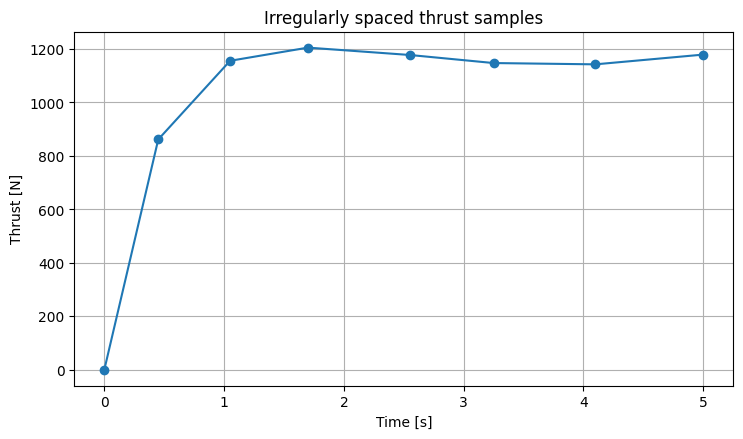

,method,partial_impulse_Ns
0,trapezoid,5408.72213
1,SciPy Simpson,5481.71266


In [ ]:
irregular_time_s = np.array([0.0, 0.45, 1.05, 1.70, 2.55, 3.25, 4.10, 5.00])
irregular_thrust_N = underlying_thrust_N(irregular_time_s)

irregular_results = pd.DataFrame({
    "method": ["trapezoid", "SciPy Simpson"],
    "partial_impulse_Ns": [
        trapezoid(irregular_thrust_N, x=irregular_time_s),
        simpson(irregular_thrust_N, x=irregular_time_s),
    ],
})

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(irregular_time_s, irregular_thrust_N, marker="o")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title("Irregularly spaced thrust samples")
ax.grid(True)
plt.show()

irregular_results


## 📂 6.1.11 Ordering and sign

Integration follows the sequence of the supplied coordinates:

* increasing coordinates integrate from left to right;
* decreasing coordinates reverse the bounds and change the sign; and
* shuffled coordinates create a path that jumps forwards and backwards.

SciPy and NumPy do not automatically sort an `x` array for integration. Sort linked
coordinates and measurements together only when chronological or spatial order is
genuinely intended.


In [ ]:
ordered_value = trapezoid(measured_thrust_N, x=sample_time_s)
reversed_value = trapezoid(
    measured_thrust_N[::-1],
    x=sample_time_s[::-1],
)

shuffle_order = np.array([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15, 18, 17, 20, 19])
shuffled_value = trapezoid(
    measured_thrust_N[shuffle_order],
    x=sample_time_s[shuffle_order],
)

pd.DataFrame({
    "coordinate order": ["increasing", "decreasing", "shuffled"],
    "computed_integral_Ns": [ordered_value, reversed_value, shuffled_value],
    "interpretation": [
        "forward accumulation",
        "same path with reversed bounds",
        "unsupported order for this time history",
    ],
})


,coordinate order,computed_integral_Ns,interpretation
0,increasing,10733.65729,forward accumulation
1,decreasing,-10733.65729,same path with reversed bounds
2,shuffled,9870.91017,unsupported order for this time history


### ⚠️ Engineering warning

A result can be numerically computed and still lack physical meaning. Before
integrating, verify:

* coordinate order;
* units and unit conversions;
* missing or duplicated nodes;
* whether the bounds represent the intended event; and
* whether the samples capture important peaks or transitions.


## 📂 6.1.12 Integrating several tests along an axis

Engineering datasets often contain several repeated tests sampled at the same times.
SciPy can integrate along a selected array axis, avoiding a manual loop.


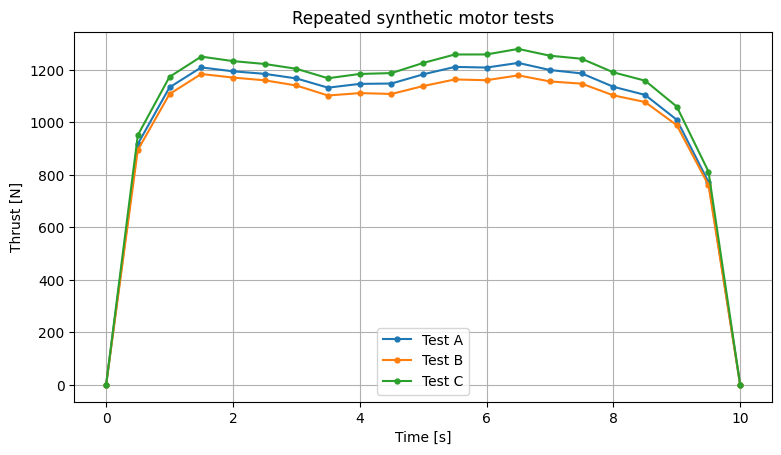

,test,total_impulse_Ns
0,Test A,10733.65729
1,Test B,10425.63228
2,Test C,11155.97624


In [ ]:
repeated_thrust_tests_N = np.vstack([
    measured_thrust_N,
    0.97 * measured_thrust_N + 12.0 * np.sin(0.8 * sample_time_s),
    1.04 * measured_thrust_N - 10.0 * np.sin(0.55 * sample_time_s),
])
repeated_thrust_tests_N[:, [0, -1]] = 0.0

repeated_impulse_Ns = trapezoid(
    repeated_thrust_tests_N,
    x=sample_time_s,
    axis=1,
)

repeated_summary = pd.DataFrame({
    "test": ["Test A", "Test B", "Test C"],
    "total_impulse_Ns": repeated_impulse_Ns,
})

fig, ax = plt.subplots(figsize=(9, 4.8))
for label, thrust_trace in zip(repeated_summary["test"], repeated_thrust_tests_N):
    ax.plot(sample_time_s, thrust_trace, marker="o", markersize=3.5, label=label)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Thrust [N]")
ax.set_title("Repeated synthetic motor tests")
ax.grid(True)
ax.legend()
plt.show()

repeated_summary


## 📂 6.1.13 Optional interactive sampling demonstration

Run the cell below. If `ipywidgets` is available, change the number of equally spaced
samples and compare the two estimates. Only odd sample counts are offered so the
classical composite Simpson rule always has an even number of intervals.

The plotted samples come from the known teaching curve rather than the measurement-
deviation dataset. This isolates the effect of sampling density for the demonstration.


In [ ]:
def plot_sampling_demonstration(sample_count=9):
    demonstration_time_s = np.linspace(0.0, 10.0, sample_count)
    demonstration_thrust_N = underlying_thrust_N(demonstration_time_s)

    trap_value = trapezoid(demonstration_thrust_N, x=demonstration_time_s)
    simpson_value = simpson(demonstration_thrust_N, x=demonstration_time_s)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(dense_time_s, dense_thrust_N, color="0.65", label="underlying curve")
    ax.plot(
        demonstration_time_s,
        demonstration_thrust_N,
        marker="o",
        linewidth=1.8,
        label=f"{sample_count} samples",
    )
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Thrust [N]")
    ax.set_title(
        f"Trapezoid: {trap_value:.1f} N s | Simpson: {simpson_value:.1f} N s"
    )
    ax.grid(True)
    ax.legend()
    plt.show()


try:
    import ipywidgets as widgets

    widgets.interact(
        plot_sampling_demonstration,
        sample_count=widgets.IntSlider(
            value=9,
            min=5,
            max=41,
            step=2,
            description="Samples",
            continuous_update=False,
        ),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the static nine-sample case.")
    plot_sampling_demonstration(sample_count=9)


interactive(children=(IntSlider(value=9, continuous_update=False, description='Samples', max=41, min=5, step=2…

## 📂 6.1.14 Method limitations and engineering checks

Before reporting a Newton–Cotes integral, ask:

1. What physical quantity is being accumulated?
2. Are the integrand, variable, bounds and output units documented?
3. Are the coordinate and measurement arrays paired and correctly ordered?
4. Are missing, duplicated or invalid samples understood?
5. Does the selected rule satisfy its spacing and sample-count requirements?
6. Are the samples dense enough to represent peaks, oscillations and transitions?
7. Is the result sensitive to using a different defensible rule or subset?
8. Is independent reference information available for validation?
9. Does the reported precision reflect the quality of the data and method?
10. Which conclusions remain unsupported by the numerical integral?

A polished numerical result cannot recover behaviour that was never measured.


## 📂 6.1.15 Useful packages and functions

| Package | Function or technique | Purpose | Important caution |
|---|---|---|---|
| `numpy` | `diff` | Calculate panel widths | Check sign and duplicated coordinates |
| `numpy` | slicing such as `y[1:-1:2]` | Select Simpson odd/even weights | Confirm the intended axis and endpoints |
| `scipy.integrate` | `trapezoid` | Composite trapezoidal integration | Coordinates are used in supplied order |
| `scipy.integrate` | `simpson` | Composite Simpson integration | Classical requirements depend on spacing and interval count |
| `scipy.integrate` | `cumulative_trapezoid` | Accumulation at successive nodes | Use `initial=0.0` when matching input length is useful |
| NumPy arrays | `axis` argument | Integrate several traces at once | Confirm which dimension represents the integration variable |
| `matplotlib` | `fill_between`, `fill` | Visualise accumulated area | A convincing plot is not independent validation |


## 📂 6.1.16 Engineering workflow and summary

A defensible sampled-data integration workflow is:

1. define the physical accumulated quantity and its units;
2. inspect the sampled coordinate and integrand arrays;
3. check order, spacing, missing values and duplicated nodes;
4. visualise the data and integration bounds;
5. select a rule whose assumptions match the samples;
6. verify a library calculation against a transparent implementation or simple case;
7. compare another defensible rule where appropriate;
8. inspect cumulative behaviour when the progression matters; and
9. report assumptions, validation evidence, precision and limitations.

Newton–Cotes rules replace unknown behaviour between samples with local polynomial
assumptions. The trapezoidal rule uses lines; Simpson's 1/3 rule uses quadratics.
Their usefulness depends as much on the data and engineering question as on the
formula.


## 📚 References

* NIST Digital Library of Mathematical Functions, *Quadrature*, Section 3.5.
* SciPy developers, *Integration and ODEs (`scipy.integrate`)*, stable documentation.
* NumPy developers, *`numpy.trapezoid`*, stable documentation.
* NASA Glenn Research Center, *Specific Impulse* and total impulse explanation.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop the synthetic teaching
example and review code. The teaching team remains responsible for the mathematical
content, engineering interpretation, source selection and final notebook.
